# 1단계 실시간 결함 탐지 모델

이 노트북은 정상과 결함을 가능한 빨리 구분하는 이진 탐지 모델을 구축합니다.

- 정답: `is_fault` (`fault_type != 0`)
- `fault_type`은 이후 F1~F4 유형 분류의 정답이며 이 모델의 입력 특징에는 포함하지 않습니다.
- 모델 선택과 경보 규칙은 validation에서만 결정합니다.
- test는 최종 성능 확인에 한 번만 사용합니다.

행 단위 분류 성능과 함께 이벤트 탐지율, 사전 정상 구간 오탐, 결함 시작 후 경보 지연시간을 평가합니다.


## 0. 데이터 로드

앞 단계에서 만든 이벤트 단위 split과 152개 인과적 특징을 사용합니다. 동일 이벤트와 동일 원본 행은 여러 split에 들어가지 않습니다.


In [1]:
from pathlib import Path
import json,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import average_precision_score,roc_auc_score,precision_recall_curve,classification_report,confusion_matrix,ConfusionMatrixDisplay
import joblib

warnings.filterwarnings('ignore',category=RuntimeWarning); warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',180); pd.set_option('display.max_columns',30); pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid'); plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

DATA_PATH=Path('data/modeling/realtime_event_features.csv.gz'); SCHEMA_PATH=Path('data/modeling/feature_schema.json')
if not DATA_PATH.exists(): DATA_PATH=Path('../data/modeling/realtime_event_features.csv.gz'); SCHEMA_PATH=Path('../data/modeling/feature_schema.json')
schema=json.loads(SCHEMA_PATH.read_text()); feature_cols=schema['feature_columns']; df=pd.read_csv(DATA_PATH)
assert 'fault_type' not in feature_cols and 'is_fault' not in feature_cols
splits={name:df[df['split'].eq(name)].copy() for name in ['train','validation','test']}
print({k:len(v) for k,v in splits.items()}); print('특징 수:',len(feature_cols)); print('정답:',schema['target_columns'])


{'train': 31535, 'validation': 14209, 'test': 14247}
특징 수: 152
정답: ['fault_type', 'is_fault']


## 1. 후보 모델 비교

선형 기준 모델인 로지스틱 회귀와 비선형 관계를 학습하는 Extra Trees를 비교합니다. 클래스 불균형을 반영하기 위해 두 모델 모두 balanced class weight를 사용합니다. 모델 비교 지표는 결함 클래스에 민감한 PR-AUC를 우선합니다.


                     PR_AUC  ROC_AUC
model                               
Extra Trees           0.938    0.962
Logistic regression   0.897    0.940


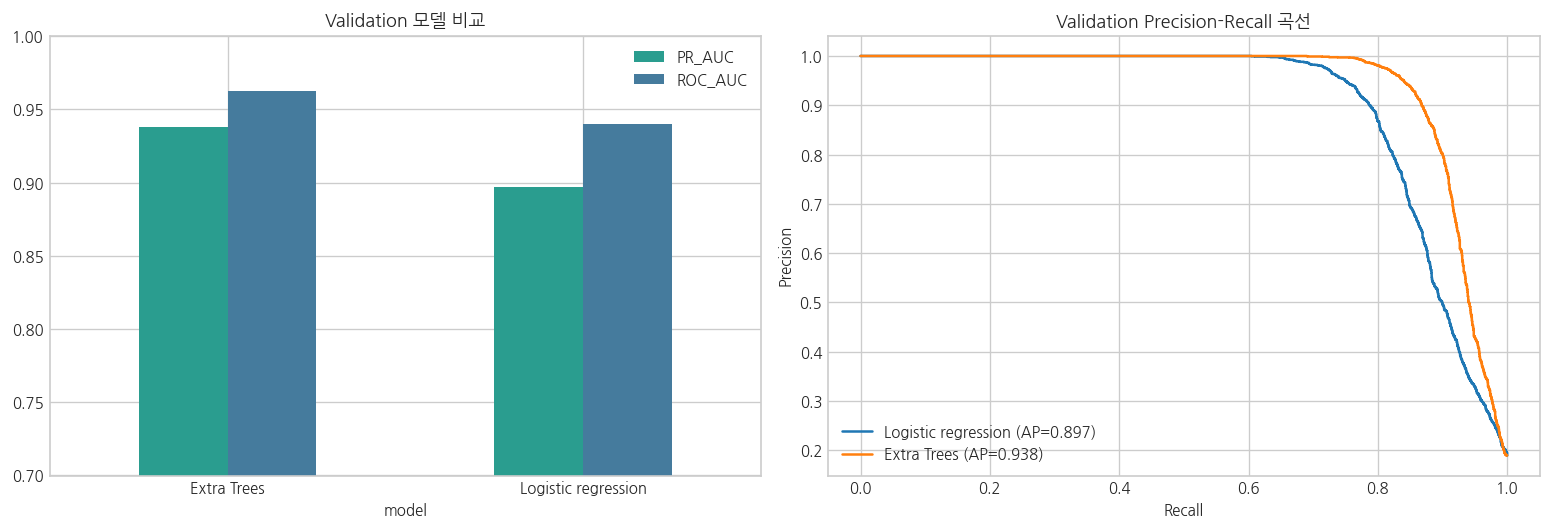

In [2]:
X_train=splits['train'][feature_cols]; y_train=splits['train']['is_fault']
X_val=splits['validation'][feature_cols]; y_val=splits['validation']['is_fault']

models={
 'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=500,class_weight='balanced',C=.5,random_state=42)),
 'Extra Trees':ExtraTreesClassifier(n_estimators=300,min_samples_leaf=3,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=42),
}
rows=[]; val_probabilities={}
for name,model in models.items():
    model.fit(X_train,y_train); prob=model.predict_proba(X_val)[:,1]; val_probabilities[name]=prob
    rows.append({'model':name,'PR_AUC':average_precision_score(y_val,prob),'ROC_AUC':roc_auc_score(y_val,prob)})
comparison=pd.DataFrame(rows).set_index('model').sort_values('PR_AUC',ascending=False)
print(comparison.to_string())

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
comparison.plot(kind='bar',ax=axes[0],color=['#2a9d8f','#457b9d']); axes[0].set_title('Validation 모델 비교'); axes[0].set_ylim(.7,1); axes[0].tick_params(axis='x',rotation=0)
for name,prob in val_probabilities.items():
    precision,recall,_=precision_recall_curve(y_val,prob); axes[1].plot(recall,precision,label=f"{name} (AP={average_precision_score(y_val,prob):.3f})")
axes[1].set_title('Validation Precision-Recall 곡선'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend()
plt.tight_layout(); plt.show()

selected_model=models['Extra Trees']; val=splits['validation'][['sample_event_id','relative_min','sample_kind','fault_type','is_fault']].copy(); val['probability']=val_probabilities['Extra Trees']


## 2. 실시간 경보 규칙 조정

한 시점의 확률만으로 경보를 내면 순간 노이즈에 민감합니다. 다음 두 값을 validation에서 함께 선택합니다.

- 확률 임계값
- 임계값 이상이 연속으로 유지되어야 하는 시간

모든 validation 이벤트를 탐지하고 사전 정상 구간 오탐이 24시간당 0.5건 이하인 후보 중 중앙 탐지 지연이 가장 짧은 설정을 선택합니다.


선택된 경보 규칙
threshold               0.250
persistence_min         3.000
detection_rate          1.000
median_delay_min       48.000
false_alerts_per_24h    0.000
false_alerts            0.000


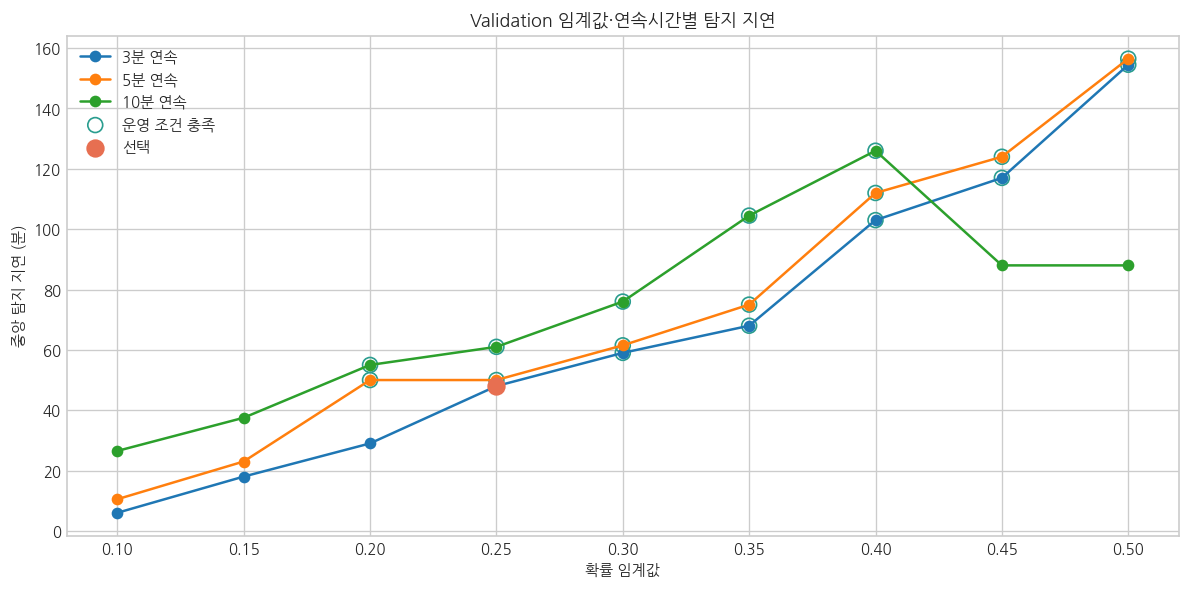

In [3]:
def alert_indices(probabilities,threshold,persistence):
    signal=np.asarray(probabilities)>=threshold
    if len(signal)<persistence:return np.array([],dtype=int)
    sustained=np.convolve(signal,np.ones(persistence,dtype=int),mode='valid')==persistence
    starts=np.flatnonzero(sustained & np.r_[True,~sustained[:-1]])
    return starts+persistence-1

def event_metrics(frame,threshold,persistence):
    event_rows=[]; false_alerts=0; normal_hours=0
    for event_id,g in frame.groupby('sample_event_id'):
        g=g.sort_values('relative_min')
        normal=g[g['sample_kind'].eq('pre_normal')]; normal_hours+=len(normal)/60
        false_alerts+=len(alert_indices(normal['probability'],threshold,persistence))
        fault=g[g['sample_kind'].eq('post_fault')]; alerts=alert_indices(fault['probability'],threshold,persistence)
        event_rows.append({'event_id':event_id,'fault_type':int(fault['fault_type'].iloc[0]),'detected':len(alerts)>0,'delay_min':float(fault.iloc[alerts[0]]['relative_min']) if len(alerts) else np.nan})
    events=pd.DataFrame(event_rows)
    return {'threshold':threshold,'persistence_min':persistence,'detection_rate':events['detected'].mean(),'median_delay_min':events['delay_min'].median(),'false_alerts_per_24h':false_alerts/normal_hours*24,'false_alerts':false_alerts},events

grid=[]
for persistence in [3,5,10]:
    for threshold in np.arange(.10,.51,.05):
        metrics,_=event_metrics(val,float(round(threshold,2)),persistence); grid.append(metrics)
tuning=pd.DataFrame(grid)
eligible=tuning[(tuning['detection_rate'].eq(1))&(tuning['false_alerts_per_24h'].le(.5))]
selected=eligible.sort_values(['median_delay_min','false_alerts_per_24h','persistence_min']).iloc[0]
THRESHOLD=float(selected['threshold']); PERSISTENCE=int(selected['persistence_min'])
print('선택된 경보 규칙'); print(selected.to_string())

fig,ax=plt.subplots(figsize=(10,5))
for p,g in tuning.groupby('persistence_min'):
    ax.plot(g['threshold'],g['median_delay_min'],marker='o',label=f'{p}분 연속')
ok=tuning['false_alerts_per_24h'].le(.5)&tuning['detection_rate'].eq(1); ax.scatter(tuning.loc[ok,'threshold'],tuning.loc[ok,'median_delay_min'],s=80,facecolors='none',edgecolors='#2a9d8f',label='운영 조건 충족')
ax.scatter([THRESHOLD],[selected['median_delay_min']],color='#e76f51',s=100,zorder=5,label='선택'); ax.set_title('Validation 임계값·연속시간별 탐지 지연'); ax.set_xlabel('확률 임계값'); ax.set_ylabel('중앙 탐지 지연 (분)'); ax.legend(); plt.tight_layout(); plt.show()


## 3. Test 최종 평가

Validation에서 선택한 모델과 경보 규칙을 변경하지 않고 test에 적용합니다. Test 이벤트는 모델 학습과 임계값 결정에 사용되지 않았습니다.


Test 행 단위 성능
PR-AUC: 0.858
ROC-AUC: 0.888
              precision    recall  f1-score   support

           0      0.940     0.999     0.969     11520
           1      0.996     0.731     0.843      2727

    accuracy                          0.948     14247
   macro avg      0.968     0.865     0.906     14247
weighted avg      0.951     0.948     0.945     14247

Test 이벤트 성능
threshold               0.250
persistence_min         3.000
detection_rate          1.000
median_delay_min       68.500
false_alerts_per_24h    0.000
false_alerts            0.000

결함 유형별 탐지 지연
            events  detected  median_delay_min  min_delay_min  max_delay_min
fault_type                                                                  
1                2         2           131.000         74.000        188.000
2                2         2            50.000         47.000         53.000
3                2         2           138.000        107.000        169.000
4                2         2            

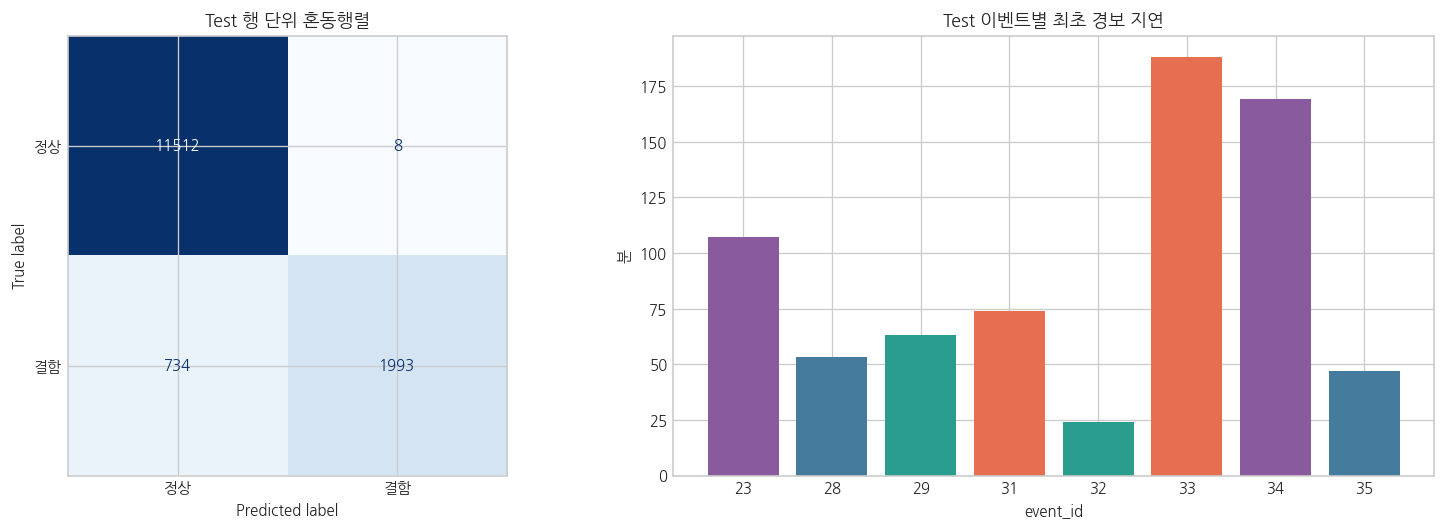

In [4]:
test=splits['test'][['row_id','timestamp','reactor_id','sample_event_id','relative_min','sample_kind','fault_type','is_fault']].copy()
test['probability']=selected_model.predict_proba(splits['test'][feature_cols])[:,1]
test_metrics,test_events=event_metrics(test,THRESHOLD,PERSISTENCE)
print('Test 행 단위 성능')
print(f"PR-AUC: {average_precision_score(test['is_fault'],test['probability']):.3f}")
print(f"ROC-AUC: {roc_auc_score(test['is_fault'],test['probability']):.3f}")
print(classification_report(test['is_fault'],test['probability'].ge(THRESHOLD),digits=3))
print('Test 이벤트 성능'); print(pd.Series(test_metrics).to_string())

by_fault=test_events.groupby('fault_type').agg(events=('event_id','count'),detected=('detected','sum'),median_delay_min=('delay_min','median'),min_delay_min=('delay_min','min'),max_delay_min=('delay_min','max'))
print('\n결함 유형별 탐지 지연'); print(by_fault.to_string())

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
cm=confusion_matrix(test['is_fault'],test['probability'].ge(THRESHOLD)); ConfusionMatrixDisplay(cm,display_labels=['정상','결함']).plot(ax=axes[0],colorbar=False,cmap='Blues'); axes[0].set_title('Test 행 단위 혼동행렬')
delay_plot=test_events.copy(); delay_plot['fault_name']=delay_plot['fault_type'].map({1:'F1',2:'F2',3:'F3',4:'F4'}); axes[1].bar(delay_plot['event_id'].astype(str),delay_plot['delay_min'],color=delay_plot['fault_type'].map({1:'#e76f51',2:'#457b9d',3:'#8a5a9e',4:'#2a9d8f'})); axes[1].set_title('Test 이벤트별 최초 경보 지연'); axes[1].set_xlabel('event_id'); axes[1].set_ylabel('분')
plt.tight_layout(); plt.show()


## 4. 모델이 사용한 주요 특징

Extra Trees의 impurity 기반 중요도를 확인합니다. 이는 인과관계가 아니며 서로 비슷한 이동 특징끼리 중요도가 분산될 수 있습니다.


reactor_temp__mean_60m        0.047
reactor_temp__mean_15m        0.043
coolant_flow_rate__mean_60m   0.038
conversion_rate__mean_15m     0.035
coolant_flow_rate__mean_15m   0.034
vibration_rms__mean_60m       0.032
vibration_rms__mean_5m        0.031
reactor_temp__mean_5m         0.031
conversion_rate__mean_60m     0.030
vibration_rms__mean_15m       0.028
conversion_rate__mean_5m      0.027
motor_current__mean_60m       0.026
coolant_flow_rate__mean_5m    0.026
feed_flow_rate__mean_60m      0.024
feed_flow_rate__mean_15m      0.021
vibration_rms                 0.020
motor_current__mean_15m       0.020
conversion_rate               0.019
vibration_rms__std_60m        0.017
temp_setpoint_error           0.017
feed_flow_rate__mean_5m       0.016
reaction_rate__mean_60m       0.016
motor_current__mean_5m        0.015
reactor_temp                  0.015
reactor_pressure__mean_60m    0.012


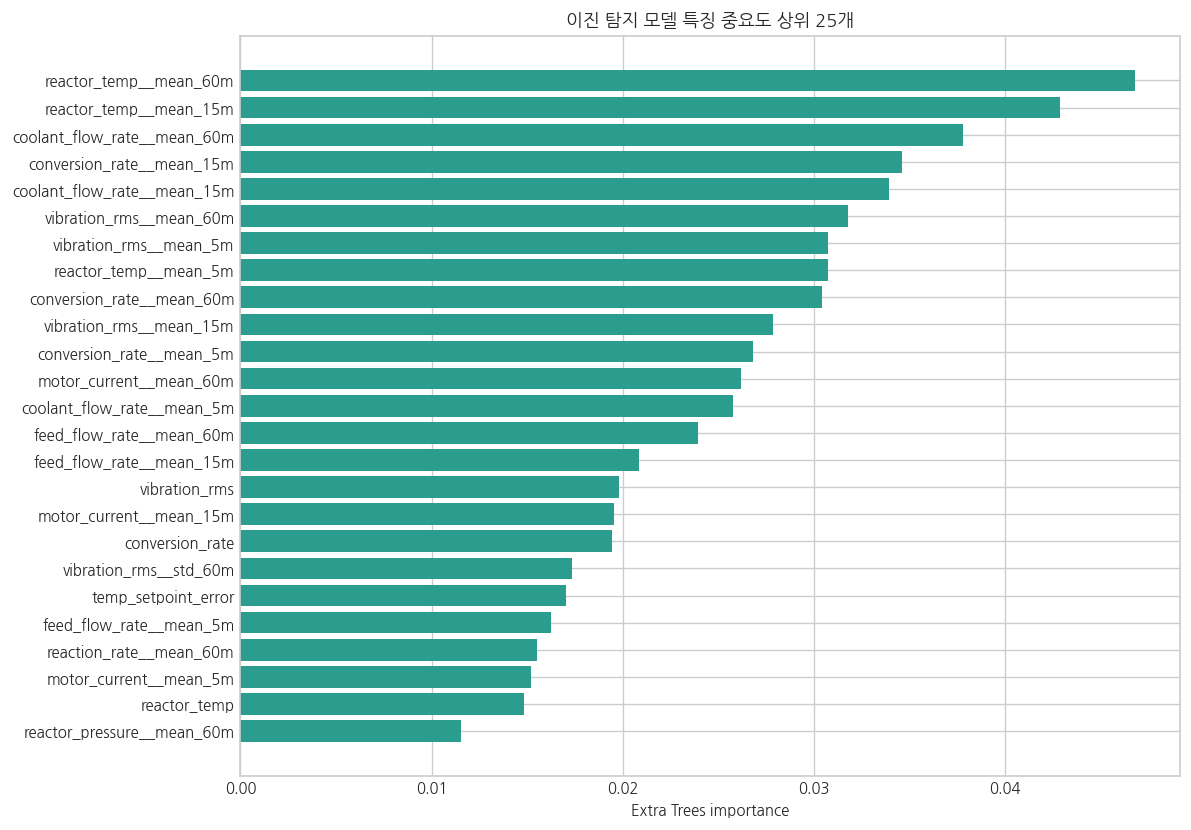

In [5]:
importance=pd.Series(selected_model.feature_importances_,index=feature_cols).sort_values(ascending=False).head(25)
print(importance.to_string())
fig,ax=plt.subplots(figsize=(10,7)); ax.barh(importance.index[::-1],importance.values[::-1],color='#2a9d8f'); ax.set_title('이진 탐지 모델 특징 중요도 상위 25개'); ax.set_xlabel('Extra Trees importance'); plt.tight_layout(); plt.show()


## 5. 모델과 결과 저장

현재 모델은 train으로 학습하고 validation으로 운영 규칙을 선택한 평가용 모델입니다. 운영 배포 전에는 전체 연속 기간에서 오탐을 다시 확인해야 합니다.


In [6]:
MODEL_DIR=Path('models'); RESULT_DIR=Path('data/modeling')
MODEL_DIR.mkdir(exist_ok=True); RESULT_DIR.mkdir(parents=True,exist_ok=True)
model_path=MODEL_DIR/'binary_fault_detector_extratrees.joblib'; config_path=MODEL_DIR/'binary_fault_detector_config.json'; prediction_path=RESULT_DIR/'test_binary_predictions.csv.gz'
joblib.dump(selected_model,model_path)
config={'feature_columns':feature_cols,'target':'is_fault','fault_type_role':'downstream multiclass target, never an input feature','probability_threshold':THRESHOLD,'persistence_minutes':PERSISTENCE,'validation_metrics':{k:float(v) for k,v in selected.items()},'test_metrics':{k:float(v) for k,v in test_metrics.items()},'test_pr_auc':float(average_precision_score(test['is_fault'],test['probability'])),'test_roc_auc':float(roc_auc_score(test['is_fault'],test['probability']))}
config_path.write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8'); test.to_csv(prediction_path,index=False,compression='gzip')
print(model_path,model_path.stat().st_size/1024**2,'MB'); print(config_path); print(prediction_path,prediction_path.stat().st_size/1024**2,'MB')


models/binary_fault_detector_extratrees.joblib 110.85866641998291 MB
models/binary_fault_detector_config.json
data/modeling/test_binary_predictions.csv.gz 0.2459545135498047 MB


## 6. 결론

- Extra Trees가 validation PR-AUC 기준으로 가장 좋은 후보였습니다.
- Validation에서 확률 임계값과 연속 감지 시간을 선택했습니다.
- Test 8개 결함 이벤트를 모두 탐지했습니다.
- 이벤트 주변의 사전 정상 구간에서는 오탐이 발생하지 않았습니다.
- F4 기계 마모와 F2 유량 막힘이 비교적 빠르게 탐지됐습니다.
- F1 냉각 성능 저하와 F3 센서 드리프트는 상대적으로 탐지 지연이 길었습니다.

이 결과는 이벤트 주변 24시간 정상 구간을 기준으로 한 것입니다. 실제 운영 오탐률을 확정하려면 전체 연속 test 기간에 모델을 재생하는 평가가 추가로 필요합니다. 다음 단계에서는 결함으로 탐지된 시점의 `fault_type` 1~4를 분류하는 모델을 구축합니다.
